# Michaud Resampled Efficient Frontier

Classical mean-variance portfolios can be highly sensitive to small changes in expected returns and covariances. This notebook evaluates whether Michaud-style resampling produces a more stable maximum-Sharpe allocation in the 23-ETF core universe.

## Estimation error and unstable efficient frontiers

Expected returns and covariance matrices are estimated rather than known. Sampling noise can materially shift an estimated efficient frontier, and optimized portfolios may amplify this noise through concentrated allocations. A portfolio that is optimal for one sample can therefore be fragile out of sample.

## Resampling intuition

At each monthly rebalance date, the engine uses the preceding 60 returns only. It estimates arithmetic expected returns and a Ledoit-Wolf covariance matrix, simulates alternative capital-market assumptions under multivariate-normal sampling theory, solves the same long-only 25%-capped maximum-Sharpe problem for each simulation, and averages the resulting weights. The 100-, 250-, and 500-resample portfolios use nested common random draws, making their differences interpretable as convergence rather than unrelated Monte Carlo noise.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
summary = pd.read_csv(PROJECT_ROOT / 'outputs/tables/michaud_summary.csv')
comparison = pd.read_csv(PROJECT_ROOT / 'outputs/tables/markowitz_vs_michaud.csv')
summary

   n_resamples  annualized_geometric_return  annualized_volatility  sharpe_ratio  max_drawdown  annualized_turnover  average_effective_number_of_assets  average_herfindahl_index
0          100                     0.092338               0.079545      0.902569     -0.204850             0.915265                            6.226498                  0.163476
1          250                     0.092213               0.079703      0.899497     -0.205291             0.814508                            6.232977                  0.163252
2          500                     0.092311               0.079813      0.899501     -0.205088             0.779960                            6.237996                  0.163112

In [2]:
comparison

                 strategy  n_resamples  annualized_geometric_return  annualized_volatility  sharpe_ratio  max_drawdown  annualized_turnover  average_effective_number_of_assets  average_herfindahl_index
0  Max Sharpe Ledoit-Wolf          NaN                     0.098585               0.084506      0.922408     -0.220241             0.880606                            4.765174                  0.212609
1             Michaud 100        100.0                     0.092338               0.079545      0.902569     -0.204850             0.915265                            6.226498                  0.163476
2             Michaud 250        250.0                     0.092213               0.079703      0.899497     -0.205291             0.814508                            6.232977                  0.163252
3             Michaud 500        500.0                     0.092311               0.079813      0.899501     -0.205088             0.779960                            6.237996                 

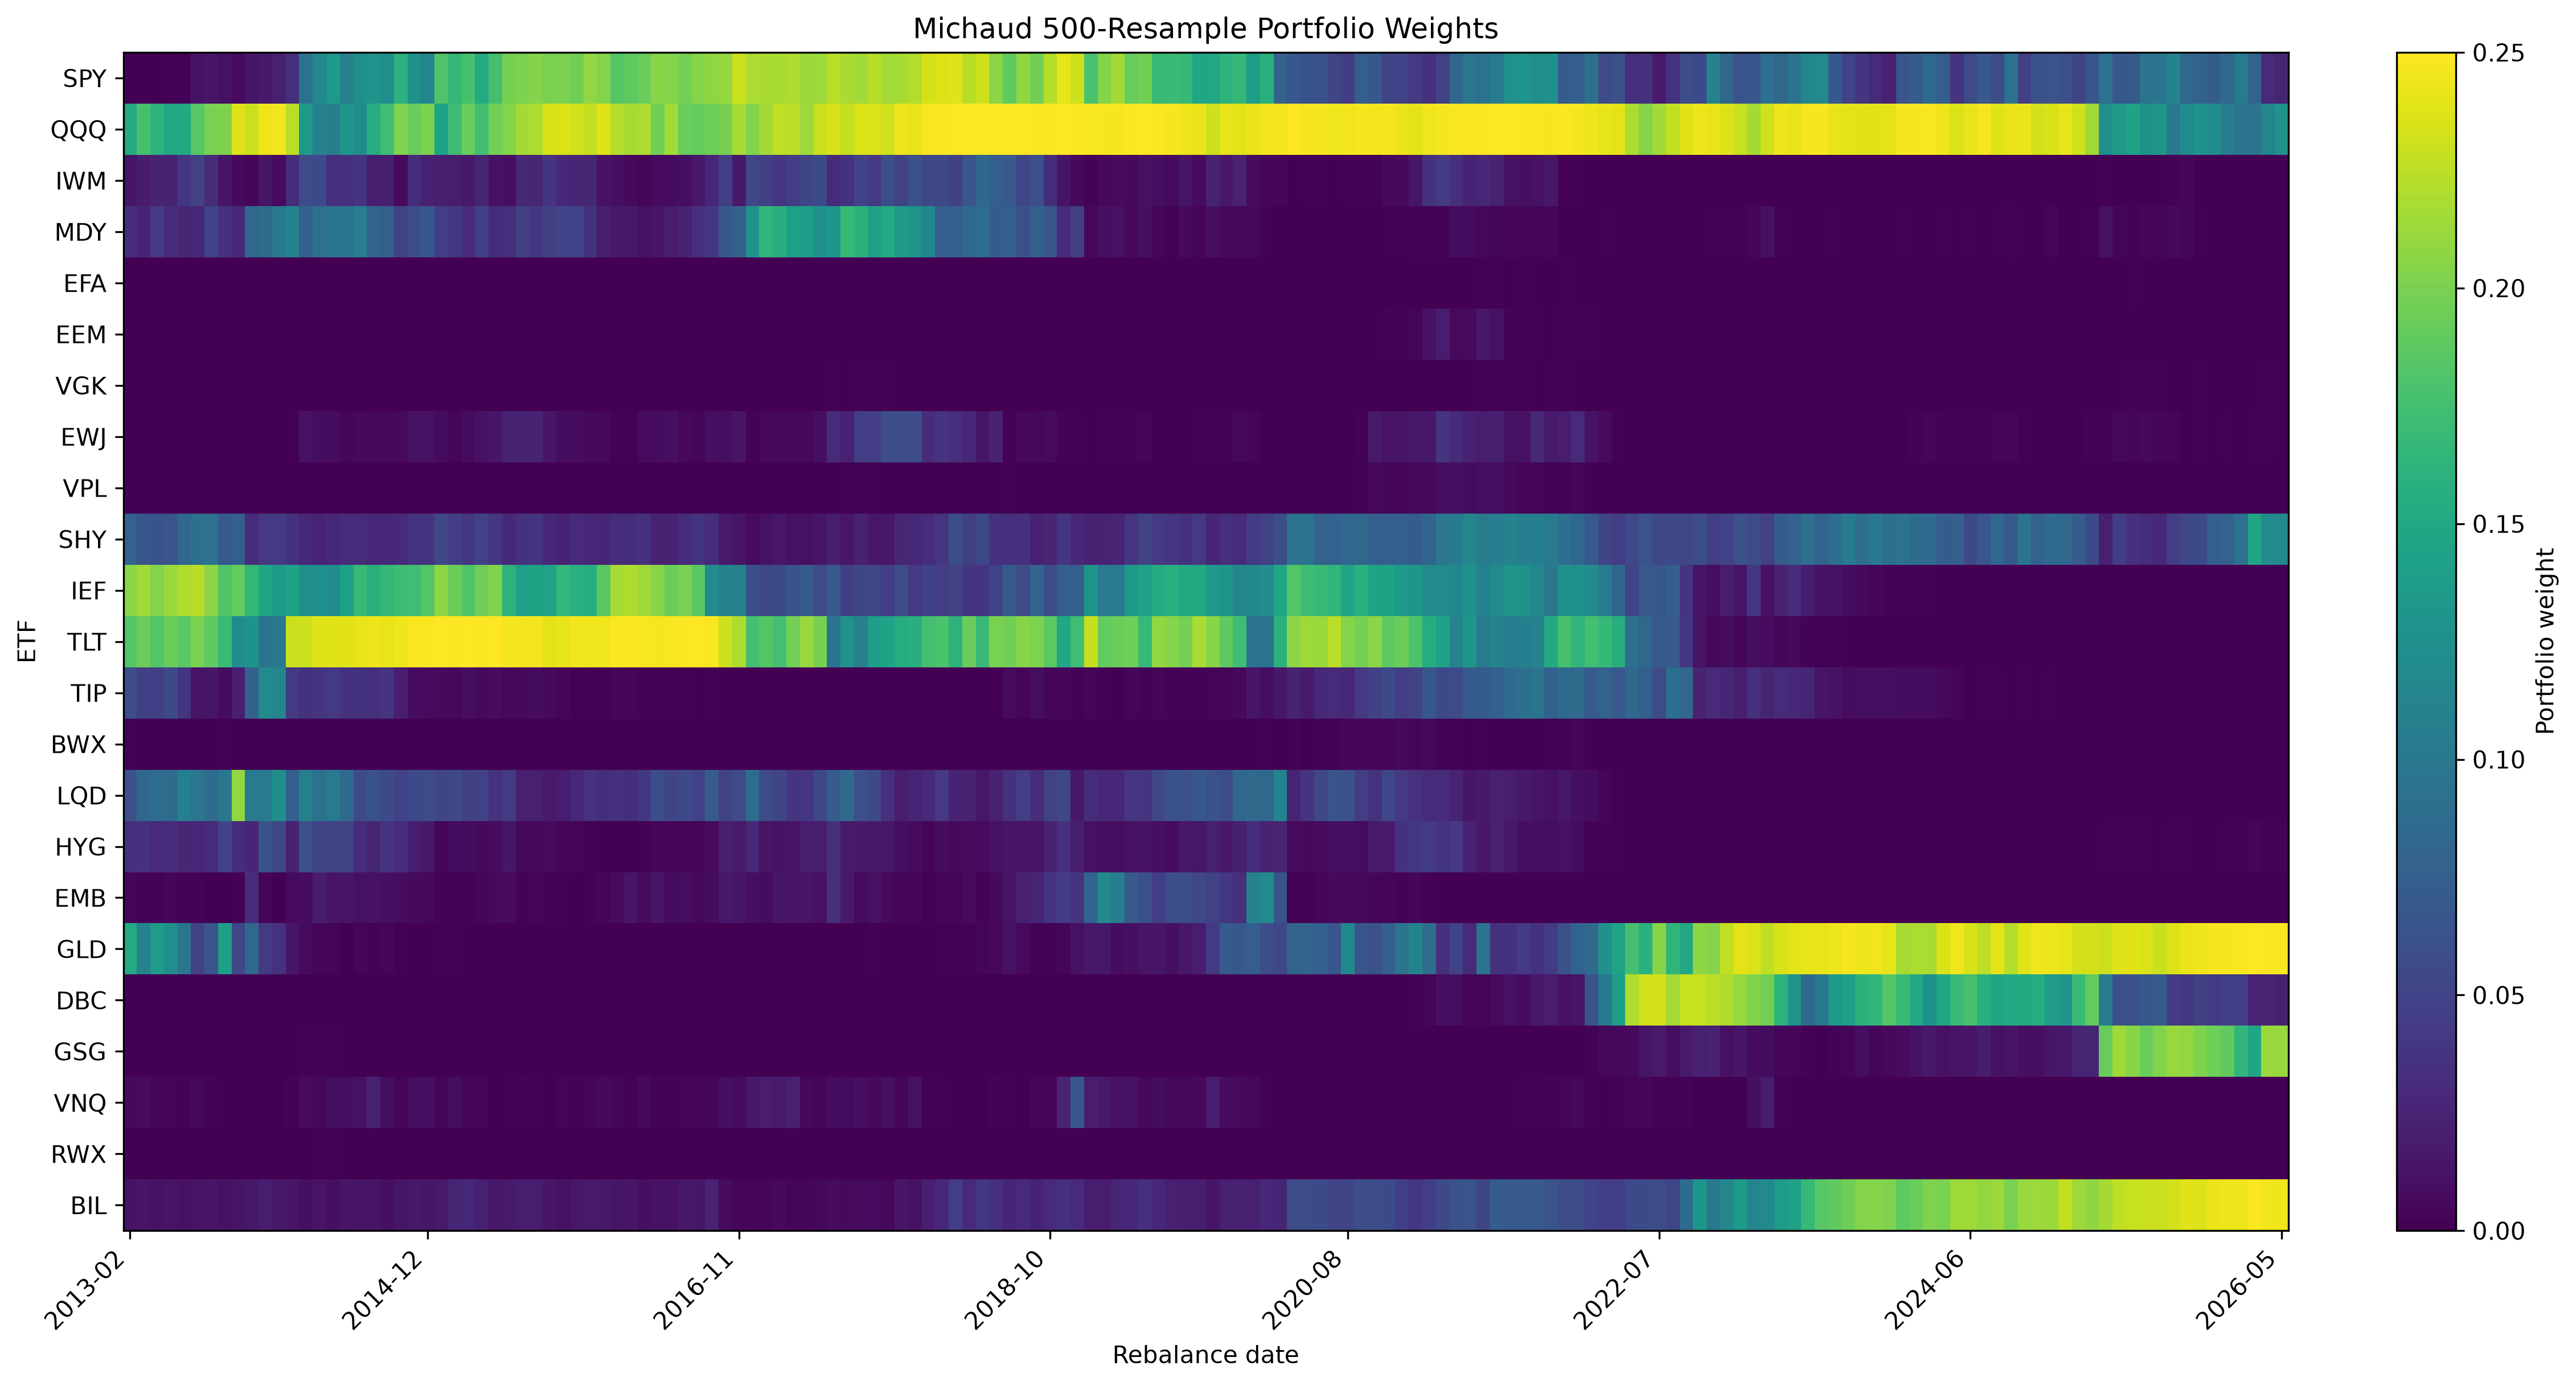

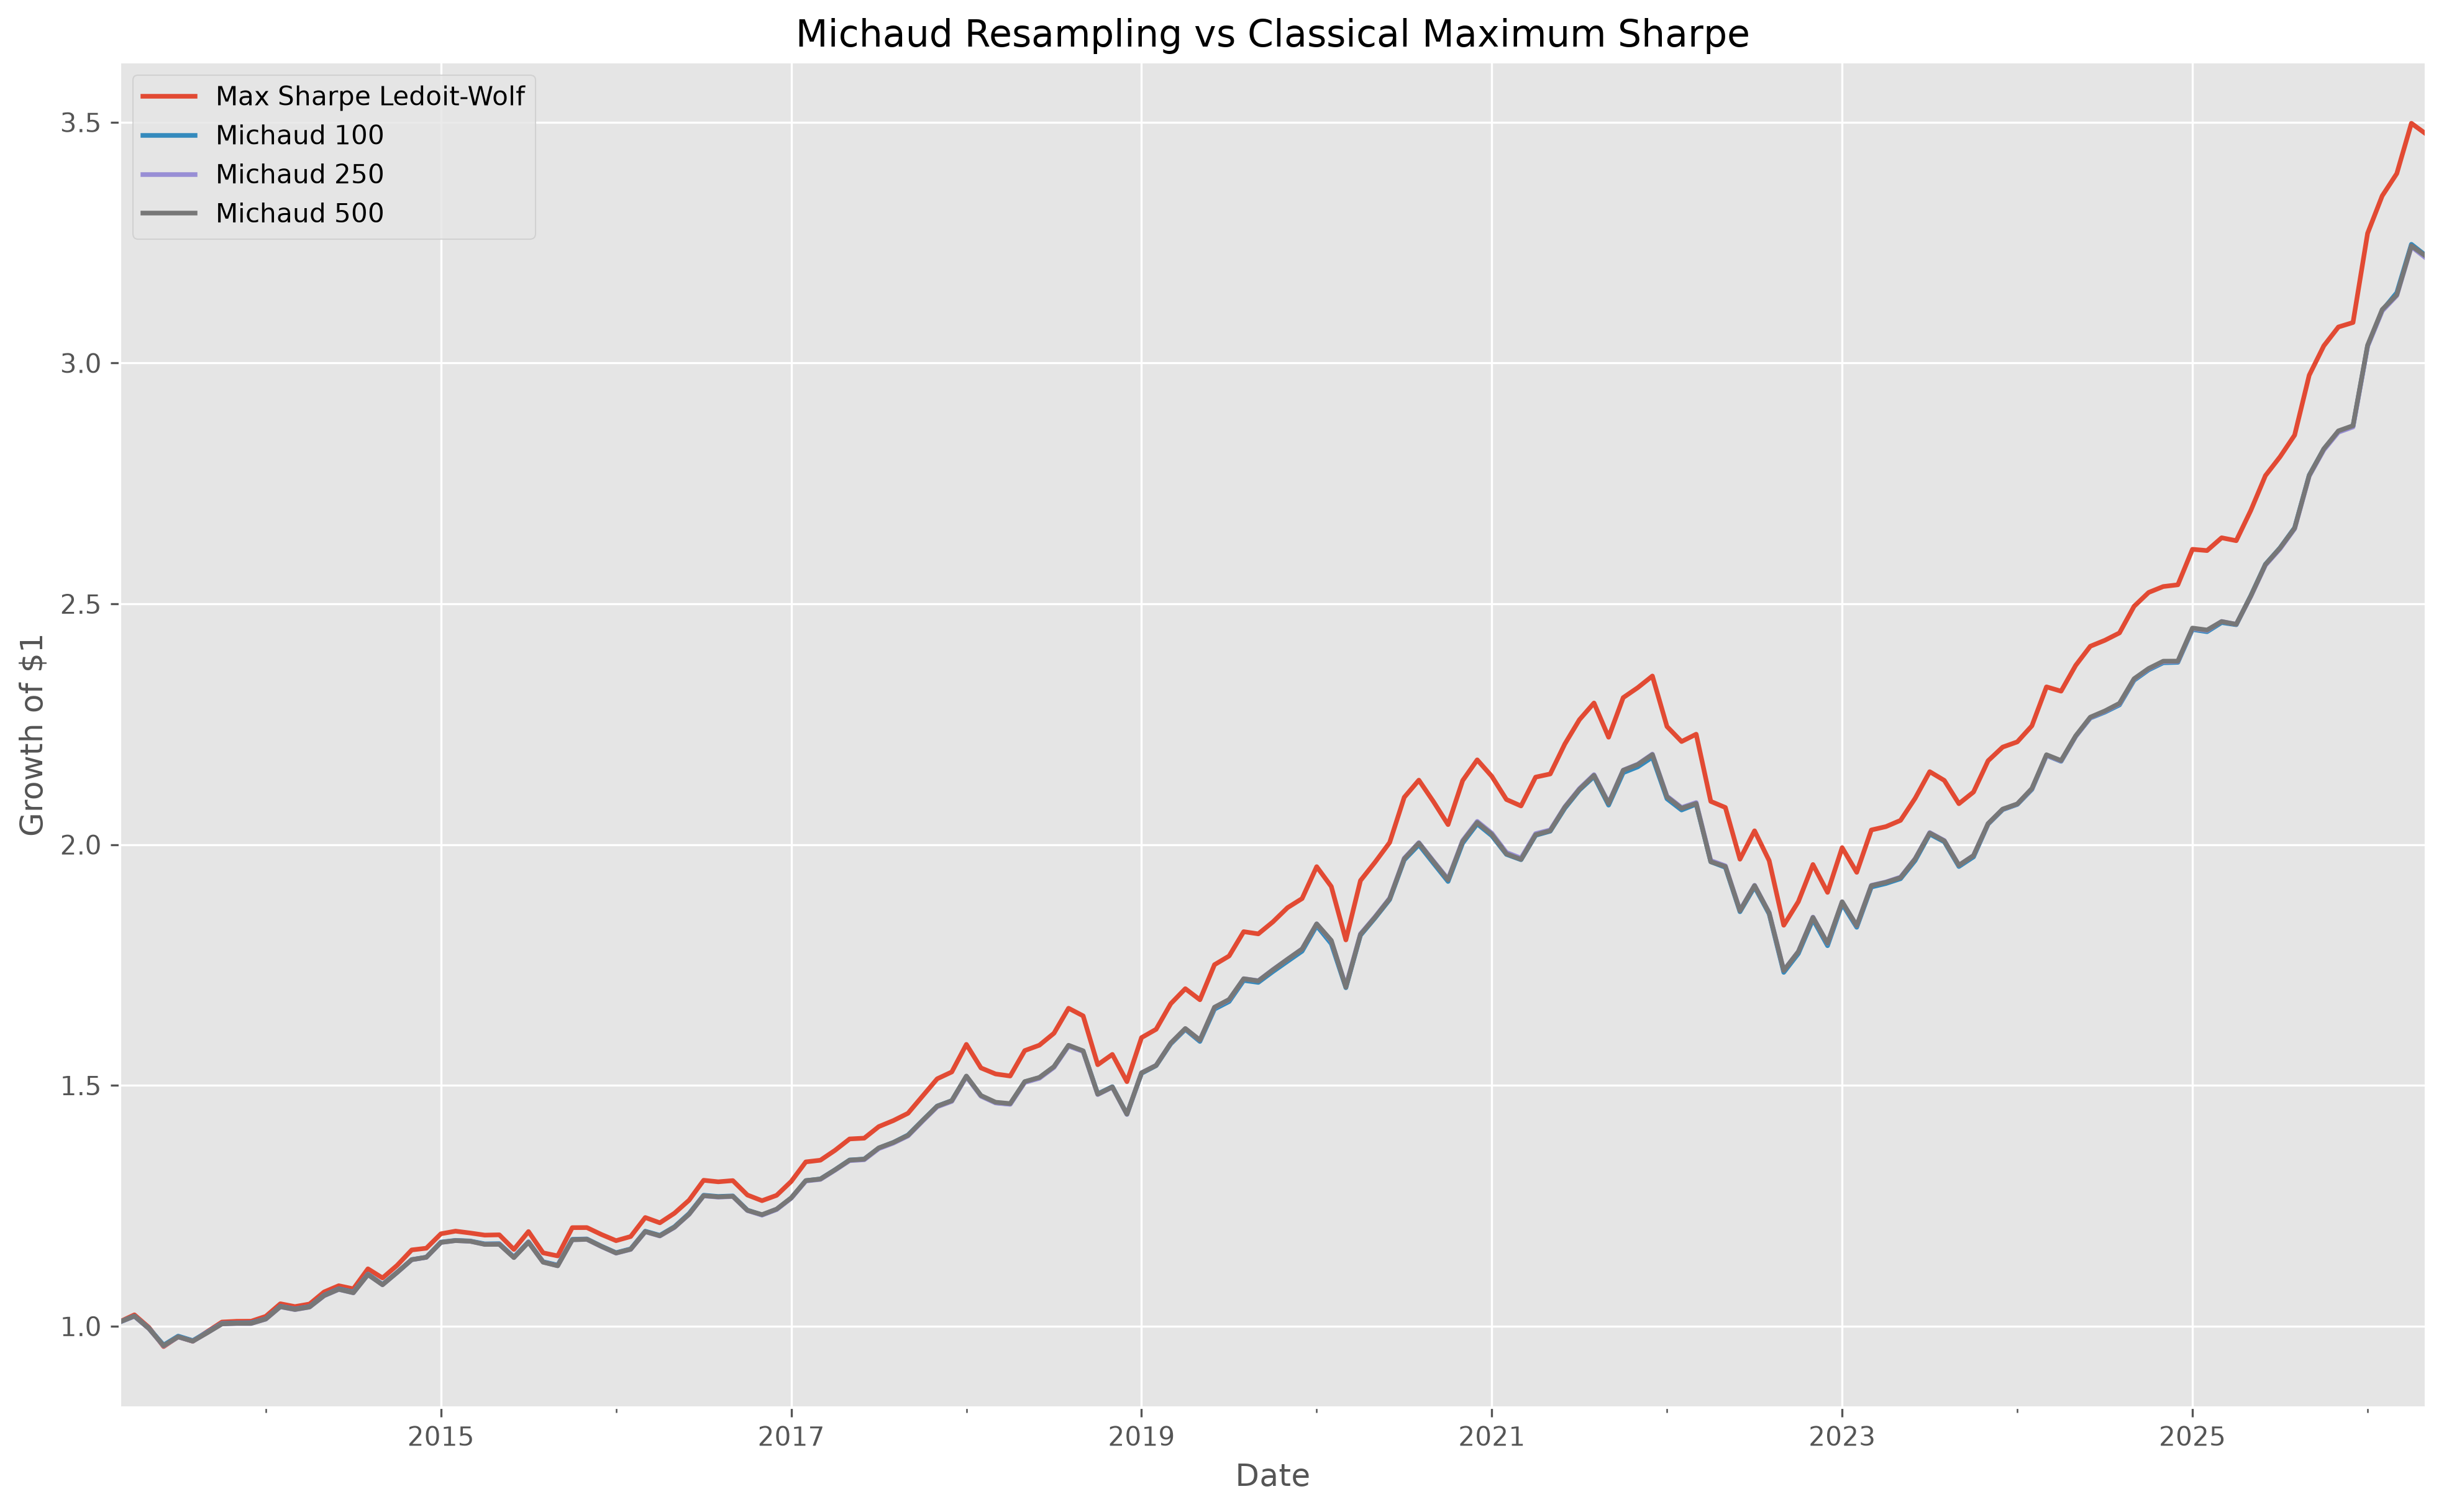

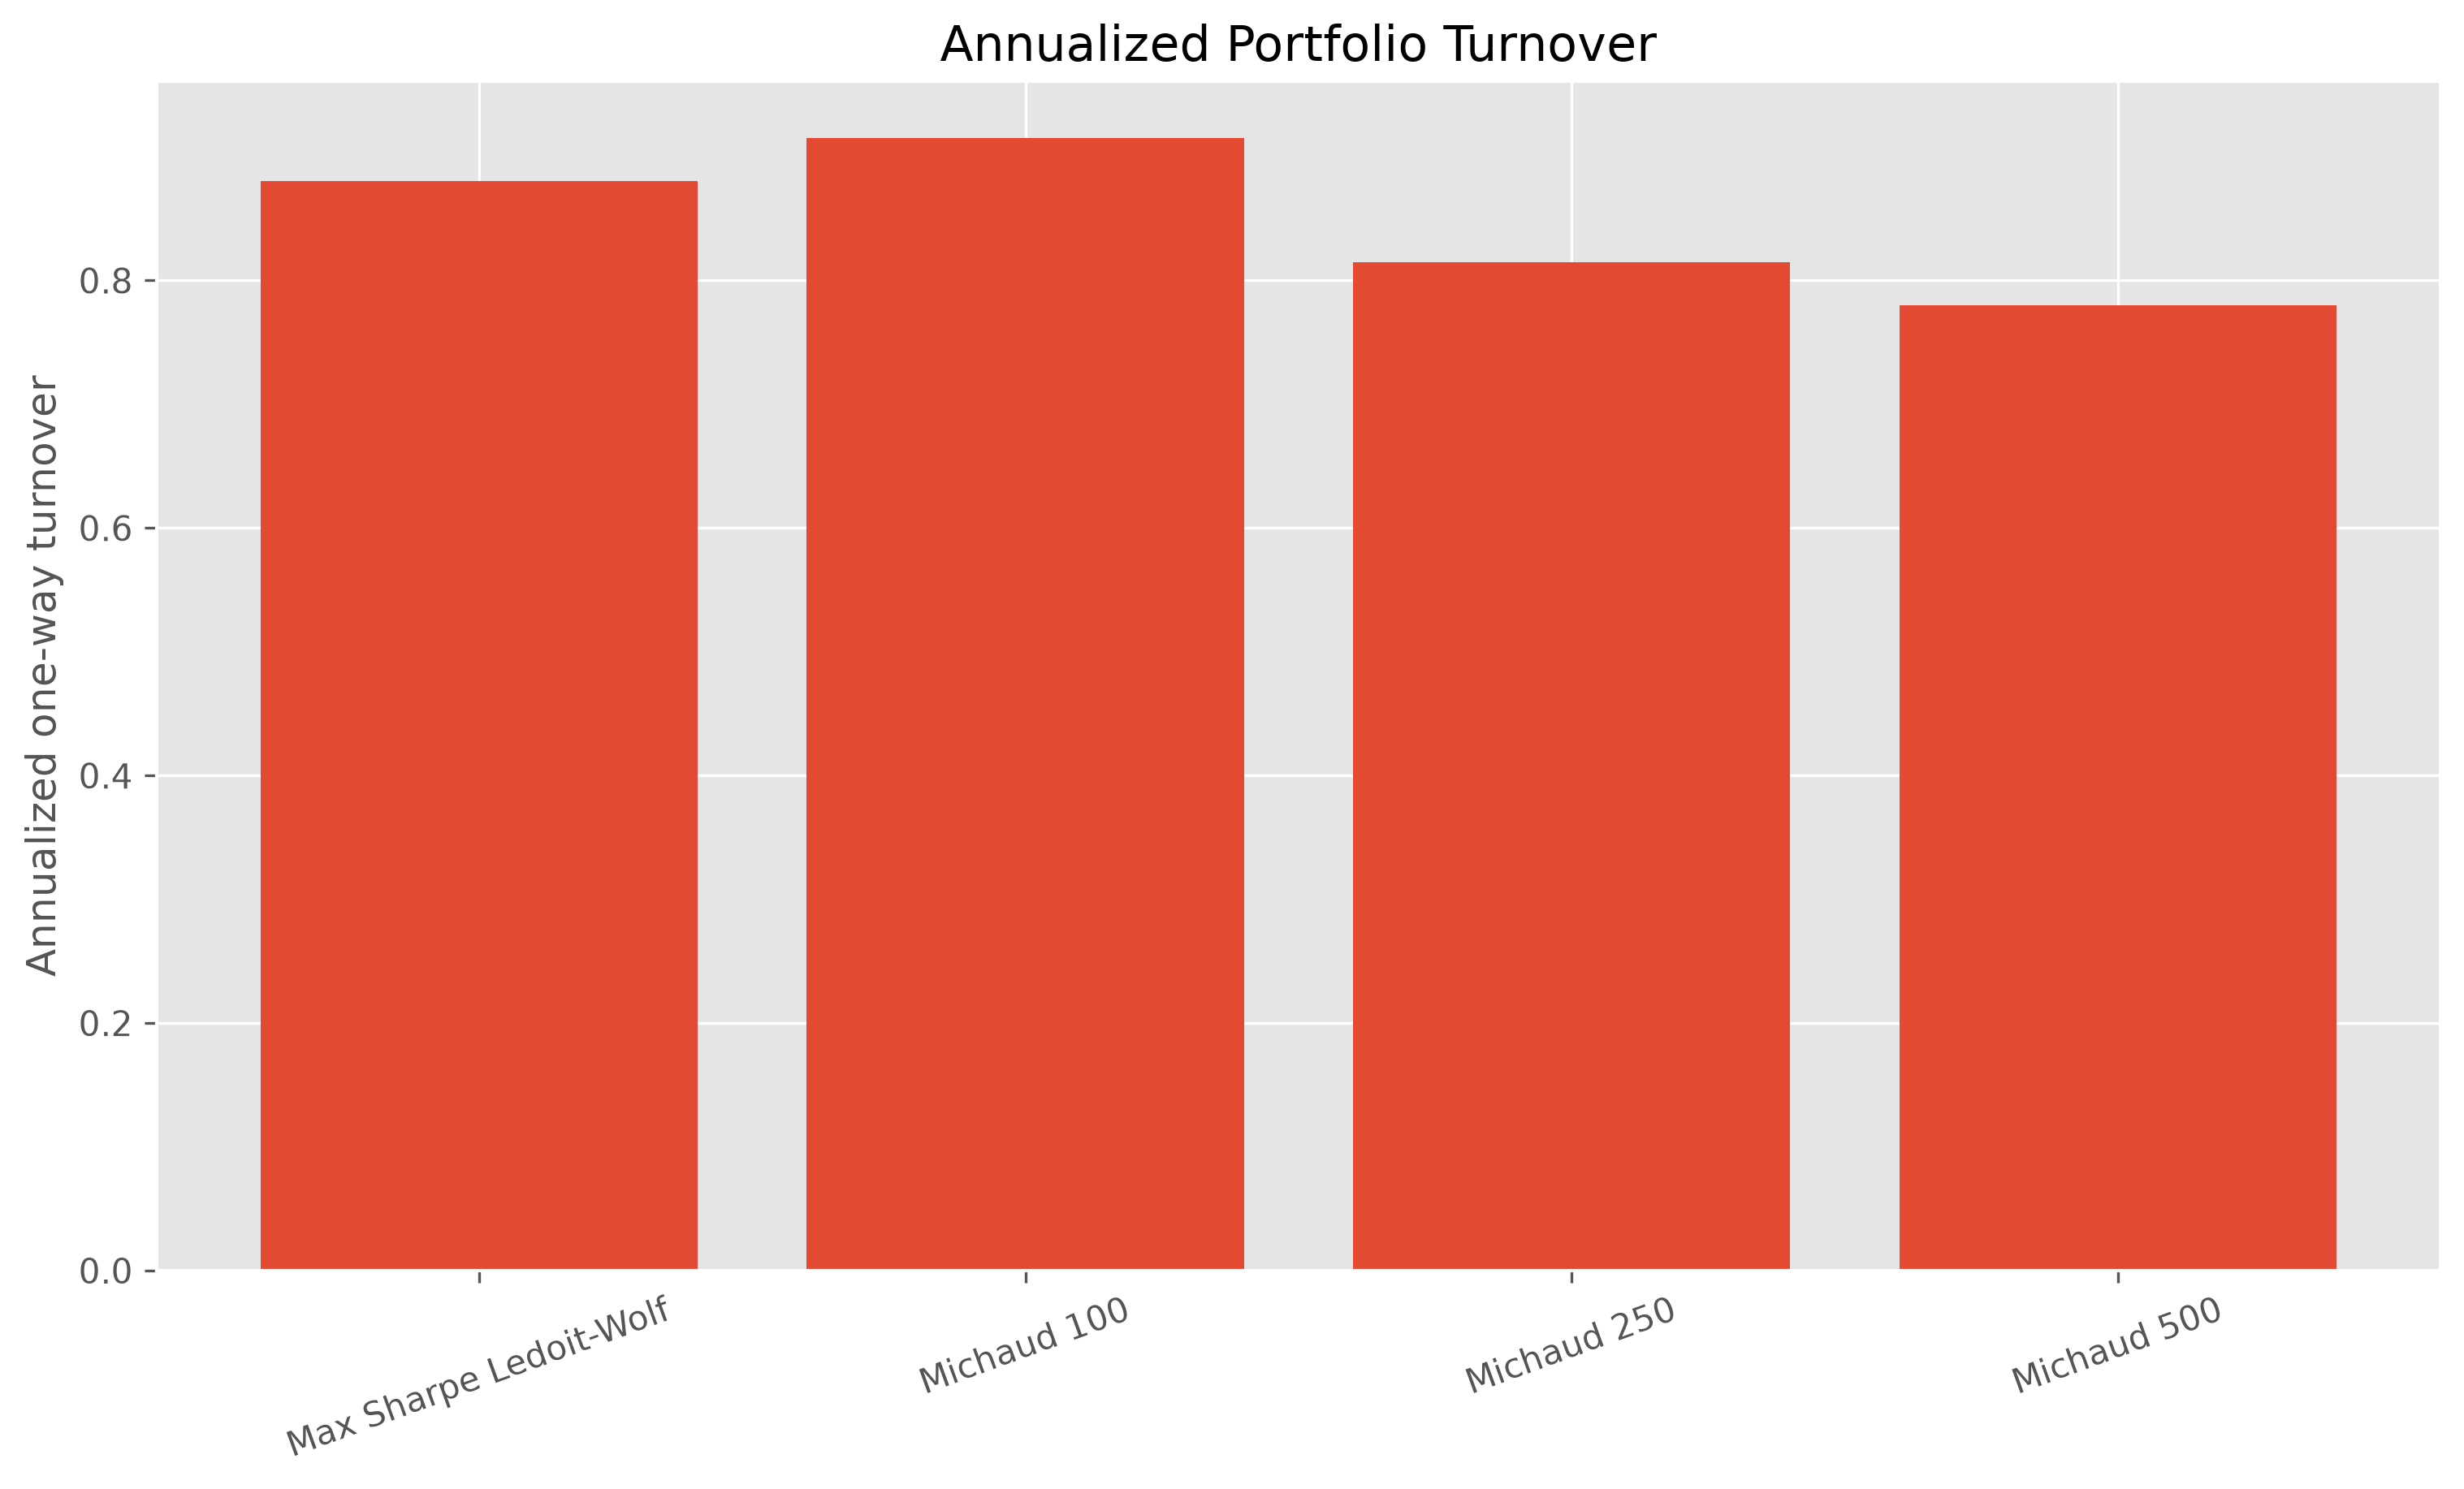

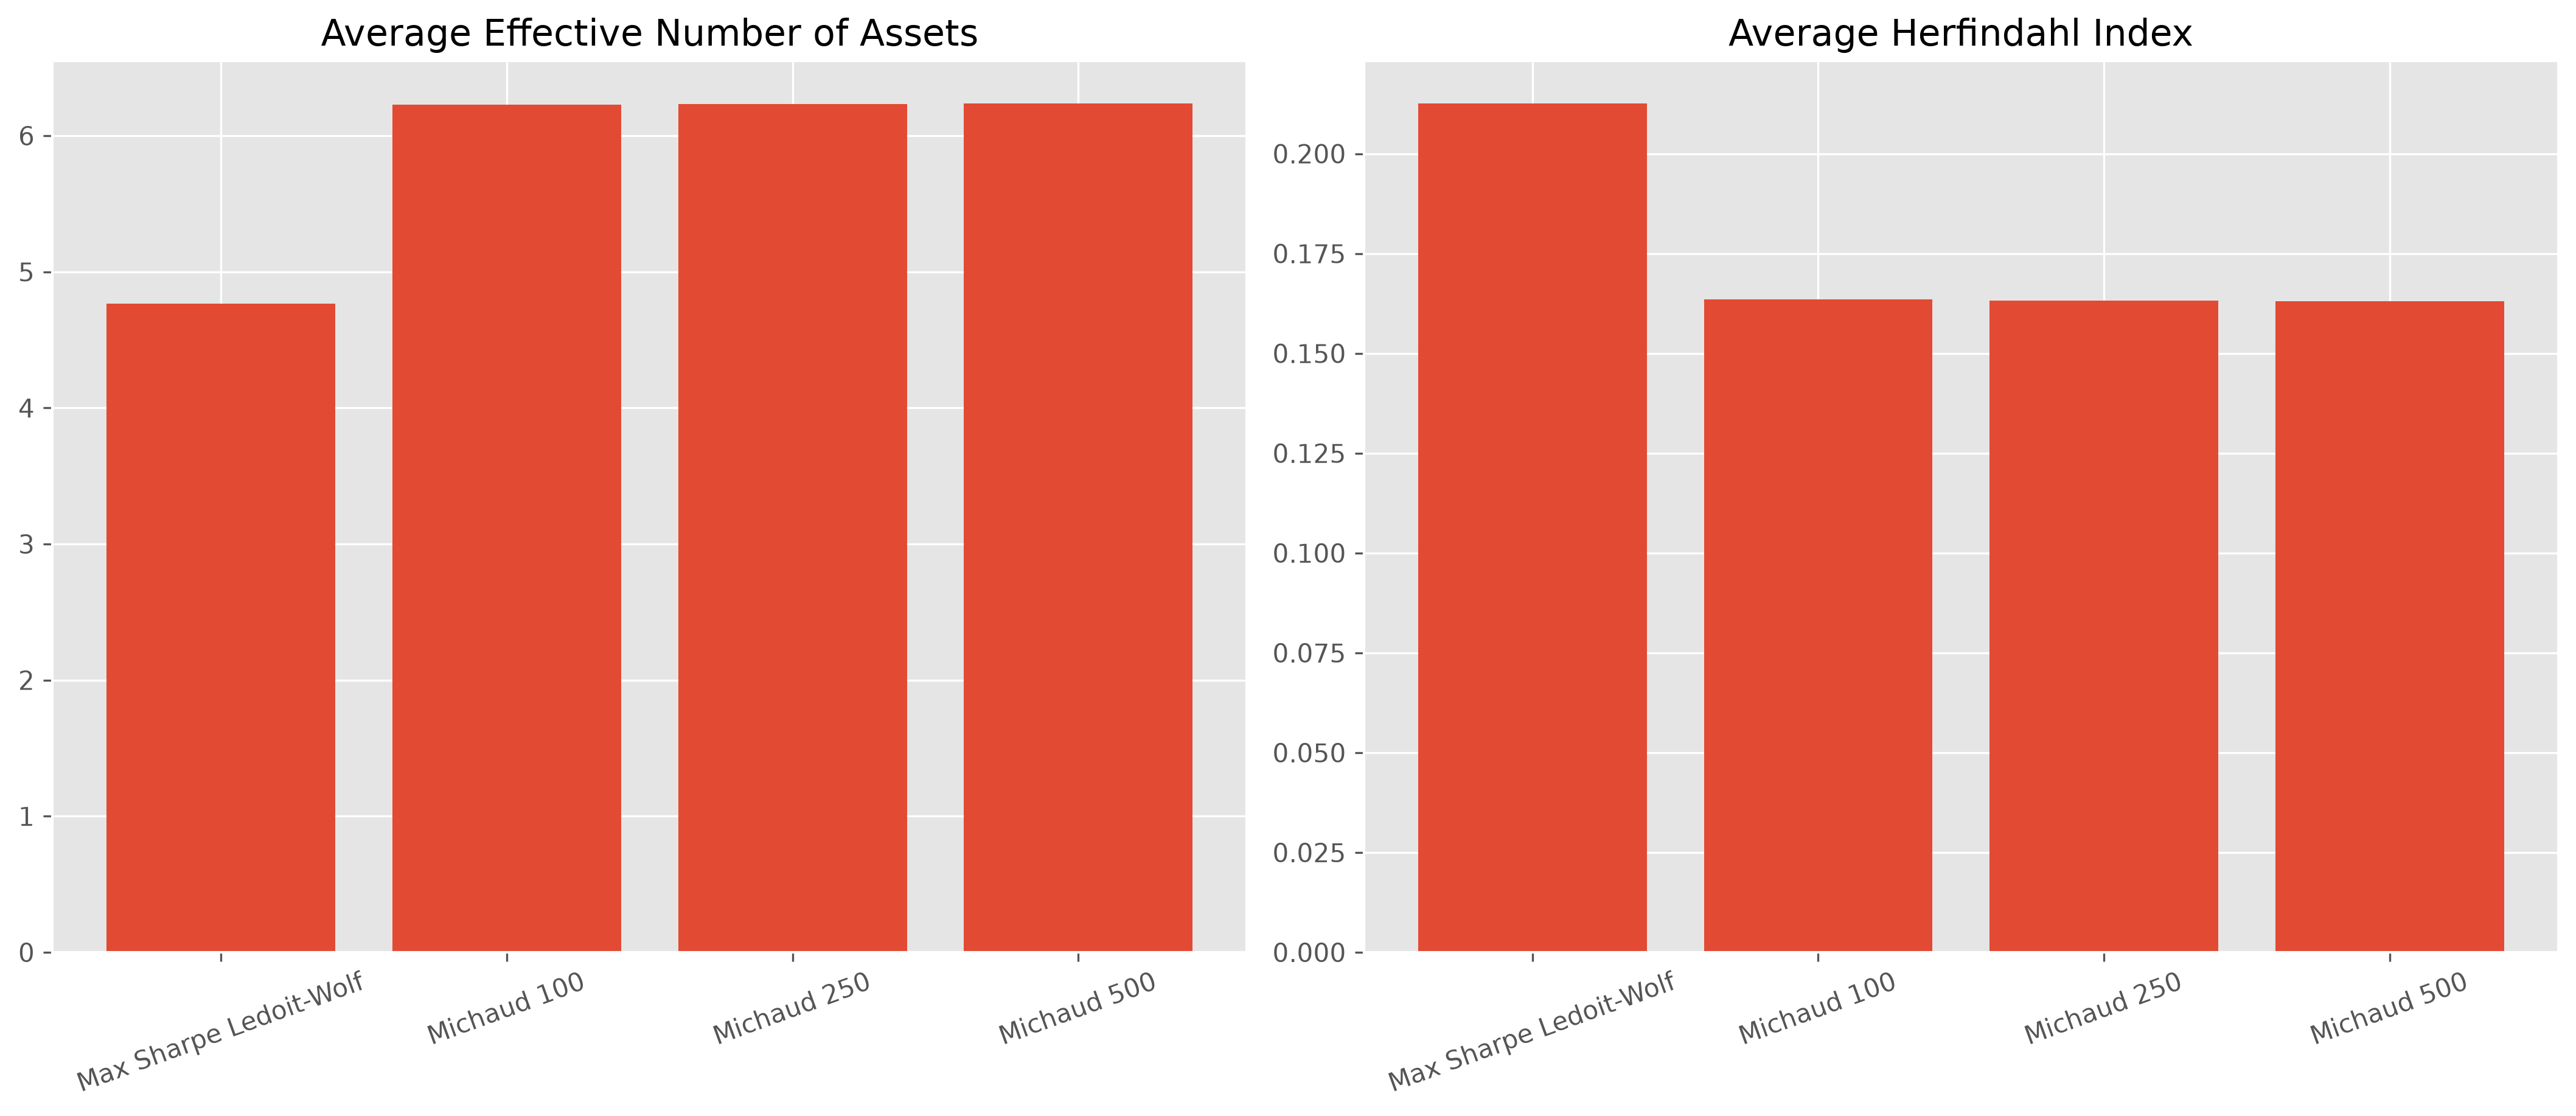

In [3]:
for figure_name in [
    'michaud_weight_heatmap.png',
    'michaud_vs_markowitz_equity_curve.png',
    'michaud_vs_markowitz_turnover.png',
    'michaud_vs_markowitz_diversification.png',
]:
    display(Image(filename=str(PROJECT_ROOT / 'outputs/figures' / figure_name)))

## Empirical interpretation

The tables and figures compare realized next-month returns after 5 bps transaction costs, turnover, concentration, and effective asset counts. The key empirical question is whether averaging portfolios across plausible estimates reduces concentration and turnover without sacrificing too much realized risk-adjusted performance. Differences among 100, 250, and 500 resamples also indicate whether the Monte Carlo average has stabilized.